# HSA_Cam_B_012.py
This file uses the LHHW_Model of kinetics to determine kinetic parameters and an optimal next experiment.

HSA_Cam_B_006.py is the model. This uses homoscedastic noise. Additionally, most parameters are at their expected values to investigate the behavior of the KL Divergence.
Here, we use the KDE method to calculate the KLD between two proposal positions.

### Plan:
* Instantiate the model on a single proposed temperature 
* Run inference
* Check that the HDI is reasonable
* calculate the KLD for the already observed temperature and a new proposed temperature


### Results:


In [1]:
import jax.numpy as jnp
import jax
import numpy as np
import matplotlib.pyplot as plt

import pymc as pm
import pytensor

import arviz as az
from scipy.optimize import minimize
from scipy.stats import gaussian_kde
from scipy.integrate import simpson
import xarray

In [2]:
from HSA_Cam_B_006 import (
    SIDX,
    TRUE_PARAMS,
    _kinetics_model,
    input_p,
    bmodel,
)

# pytensor.config.mode = "JAX"

In [3]:
def post_model_over_T(proposal, idata, key="posterior"):

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        "k0": idata[key]["k0"].values.reshape(1, -1),
        "Ea_k": idata[key]["Ea_k"].values.reshape(1, -1),
        "A_oh": idata[key]["A_oh"].values.reshape(1, -1),
        "dH_oh": idata[key]["dH_oh"].values.reshape(1, -1),
        "A_h2": idata[key]["A_h2"].values.reshape(1, -1),
        "dH_h2": idata[key]["dH_h2"].values.reshape(1, -1),
        "A_mix": idata[key]["A_mix"].values.reshape(1, -1),
        "dH_mix": idata[key]["dH_mix"].values.reshape(1, -1),
    }

    test_res = _kinetics_model(**test_params)
    return test_res


def true_model_over_T(proposal):
    true_res_T = _kinetics_model(
        input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        *TRUE_PARAMS.values(),
    )
    return true_res_T

In [4]:
def post_model_at_proposal(proposal, idata, key="posterior", n_samples=5):

    param_samples = az.extract(idata, group=key, num_samples=n_samples)

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.array(proposal[0]).reshape(1, 1),
        "k0": param_samples["k0"].values.reshape(1, -1),
        "Ea_k": param_samples["Ea_k"].values.reshape(1, -1),
        "A_oh": param_samples["A_oh"].values.reshape(1, -1),
        "dH_oh": param_samples["dH_oh"].values.reshape(1, -1),
        "A_h2": param_samples["A_h2"].values.reshape(1, -1),
        "dH_h2": param_samples["dH_h2"].values.reshape(1, -1),
        "A_mix": param_samples["A_mix"].values.reshape(1, -1),
        "dH_mix": param_samples["dH_mix"].values.reshape(1, -1),
    }

    r = _kinetics_model(**test_params)
    obs_r = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
    return obs_r

In [5]:
def plot_post_model_at_proposal(proposal, test_res, true_res, Ts):
    plt.plot(
        Ts,
        test_res.mean(axis=1),
    )
    plt.plot(
        Ts,
        true_res.squeeze(),
        color="black",
        linestyle="--",
    )
    plt.fill_between(
        x=Ts,
        y1=np.percentile(test_res, 2.5, axis=1),
        y2=np.percentile(test_res, 97.5, axis=1),
        alpha=0.3,
        zorder=0,
    )
    ax = plt.gca()
    ax.text(
        0.05,
        0.95,
        f"pred. @ p={proposal[1]:.2f}, F= {proposal[2]:.2f}, C= {proposal[3]:.2f}, H2= {proposal[4]:.2f}",
        transform=ax.transAxes,
        fontsize=10,
    )
    ax2 = ax.twinx()
    ax2.plot(
        Ts,
        (np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1))
        / np.mean(test_res, axis=1),
        color="orange",
    )

In [6]:
def observe_at_proposal(proposals):
    T = jnp.array([proposals[:, 0]], dtype=jnp.float32).reshape(-1, 1)
    p = jnp.array([proposals[:, 1]], dtype=jnp.float32).reshape(-1, 1)
    c2h = jnp.array([proposals[:, 2]], dtype=jnp.float32).reshape(-1, 1)
    f = jnp.array([proposals[:, 3]], dtype=jnp.float32).reshape(-1, 1)
    c2i = jnp.array([proposals[:, 4]], dtype=jnp.float32).reshape(-1, 1)

    p_i = input_p(p, c2h, f, c2i)

    r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
    r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
    return T, p, c2h, f, c2i, r_obs

In [7]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = input_p(p, c2h, f, c2i)
    res = _kinetics_model(
        p_i,
        T,
        idata[key]["k0"].values.reshape(1, -1),
        idata[key]["Ea_k"].values.reshape(1, -1),
        idata[key]["A_oh"].values.reshape(1, -1),
        idata[key]["dH_oh"].values.reshape(1, -1),
        idata[key]["A_h2"].values.reshape(1, -1),
        idata[key]["dH_h2"].values.reshape(1, -1),
        idata[key]["A_mix"].values.reshape(1, -1),
        idata[key]["dH_mix"].values.reshape(1, -1),
    )
    HDI = jnp.percentile(res, 97.5) - jnp.percentile(res, 2.5)
    return -HDI

In [8]:
def kl_marginal(P_samples, Q_samples, eps=1e-12):
    kde_P = gaussian_kde(P_samples)
    kde_Q = gaussian_kde(Q_samples)

    grid = np.linspace(
        min(P_samples.min(), Q_samples.min()),
        max(P_samples.max(), Q_samples.max()),
        1000,
    )

    p_vals = kde_P(grid) + eps
    q_vals = kde_Q(grid) + eps

    kld = simpson(p_vals * np.log(p_vals / q_vals), grid)
    return kld


def kl_divergence_between_models(
    idata_new,
    idata_old,
    key_new="posterior",
    key_old="posterior",
    n_samples=1000,
    var_names=None,
):
    if var_names is None:
        var_names = list(idata_new[key_new].data_vars.keys())

    old_samples = az.extract(
        idata_old,
        group=key_old,
        num_samples=n_samples,
        var_names=var_names,
    )
    new_samples = az.extract(
        idata_new,
        group=key_new,
        num_samples=n_samples,
        var_names=var_names,
    )
    klds = []
    # Compute KL divergence using marginal distributions
    for var in old_samples.data_vars:
        P_samples = new_samples[var].values.flatten()
        Q_samples = old_samples[var].values.flatten()
        kl_div = kl_marginal(P_samples, Q_samples)
        klds.append(kl_div)
    return np.array(klds)


def KL_divergence(x_old, y_old, x_new, idata_old, n_hyp_samples=5):
    """
    Compute KL divergence between posterior distributions before and after adding hypothetical data.

    KL(P_new || P_old) = E_P_new[log P_new(θ) - log P_old(θ)]

    Args:
        model: Original PyMC model
        x: Current experimental conditions
        y: Current observations
        x_new: New experimental condition to test
        idata: Current posterior samples
        key: Which group to use from idata ("posterior" or "prior")
        n_hyp_samples: Number of hypothetical observations to average over

    Returns:
        Average KL divergence across hypothetical samples
    """

    # Step 1: Generate hypothetical observations at the new experimental condition
    y_new_samples = post_model_at_proposal(
        x_new,
        idata_old,
        key="posterior",
        n_samples=n_hyp_samples,
    ).reshape(-1, 1)
    print(f"Generated {n_hyp_samples} hypothetical observations at new condition")

    # Step 2: Compute KL divergence for each hypothetical observation
    kl_values = []

    klds = xarray.DataArray(
        dims=["hyp_sample", "parameter"],
        coords={
            "hyp_sample": np.arange(n_hyp_samples),
            "parameter": [
                "Ea_k",
                "k0",
                "dH_oh",
                "dH_h2",
                "dH_mix",
                "A_oh",
                "A_h2",
                "A_mix",
                "sigma_r",
            ],
        },
        data=np.zeros((n_hyp_samples, 9)),
    )

    for i in range(n_hyp_samples):
        print(f"Processing hypothetical sample {i+1}/{n_hyp_samples}")

        # Get the i-th hypothetical observation
        y_hyp = y_new_samples[i].reshape(1, 1)

        # Create augmented dataset: combine current data with hypothetical observation
        x_augmented = jnp.vstack([x_old, x_new.reshape(1, -1)])
        y_augmented = jnp.vstack([y_old, y_hyp])

        # Build new model with augmented data
        T_aug, p_aug, c2h_aug, f_aug, c2i_aug, _ = observe_at_proposal(x_augmented)
        model_new = bmodel(
            (
                np.asarray(T_aug),
                np.asarray(p_aug),
                np.asarray(c2h_aug),
                np.asarray(f_aug),
                np.asarray(c2i_aug),
            ),
            np.asarray(y_augmented),
        )

        # Sample from the new posterior (with augmented data)
        with model_new:
            # Use fewer samples for speed, but ensure convergence
            # idata_new = pm.sample(
            #     tune=1000,
            #     draws=4000,
            #     target_accept=0.9,
            #     return_inferencedata=True,
            #     progressbar=False,  # Reduce output clutter
            # )
            approx = pm.fit(
                n=50000,
                method="advi",
                progressbar=False,
            )
            idata_new = approx.sample(
                4000,
            )

        # Step 3: Compute log probabilities for KL divergence
        # Extract parameter samples from both posteriors
        klds_i = kl_divergence_between_models(
            idata_new,
            idata_old,
            key_new="posterior",
            key_old="posterior",
            n_samples=1000,
            var_names=[
                "Ea_k",
                "k0",
                "dH_oh",
                "dH_h2",
                "dH_mix",
                "A_oh",
                "A_h2",
                "A_mix",
                "sigma_r",
            ],
        )
        klds.loc[i, :] = klds_i

    # Step 4: Return KL divergences across all hypothetical samples
    return klds

In [35]:
from multiprocessing import Pool


def _single_kl_worker(args):
    # This function must be at the top level for multiprocessing on Windows
    x_old, y_old, x_new, idata_old, y_hyp = args
    import numpy as np
    import jax.numpy as jnp
    from HSA_Cam_B_006 import bmodel, input_p, _kinetics_model, TRUE_PARAMS
    import pymc as pm
    from HSA_Cam_B_012 import observe_at_proposal, kl_divergence_between_models

    x_augmented = jnp.vstack([x_old, x_new.reshape(1, -1)])
    y_augmented = jnp.vstack([y_old, y_hyp])
    T_aug, p_aug, c2h_aug, f_aug, c2i_aug, _ = observe_at_proposal(x_augmented)
    model_new = bmodel(
        (
            np.asarray(T_aug),
            np.asarray(p_aug),
            np.asarray(c2h_aug),
            np.asarray(f_aug),
            np.asarray(c2i_aug),
        ),
        np.asarray(y_augmented),
    )
    with model_new:
        approx = pm.fit(
            n=50000,
            method="advi",
            progressbar=False,
        )
        idata_new = approx.sample(4000)
    klds_i = kl_divergence_between_models(
        idata_new,
        idata_old,
        key_new="posterior",
        key_old="posterior",
        n_samples=1000,
        var_names=[
            "Ea_k",
            "k0",
            "dH_oh",
            "dH_h2",
            "dH_mix",
            "A_oh",
            "A_h2",
            "A_mix",
            "sigma_r",
        ],
    )
    return klds_i


def mp_KL_divergence(x_old, y_old, x_new, idata_old, n_hyp_samples=5):
    # Step 1: Generate hypothetical observations at the new experimental condition
    y_new_samples = post_model_at_proposal(
        x_new,
        idata_old,
        key="posterior",
        n_samples=n_hyp_samples,
    ).reshape(-1, 1)
    print(f"Generated {n_hyp_samples} hypothetical observations at new condition")

    # Step 2: Compute KL divergence for each hypothetical observation in parallel
    args_list = [
        (x_old, y_old, x_new, idata_old, y_new_samples[i].reshape(1, 1))
        for i in range(n_hyp_samples)
    ]
    with Pool(4) as pool:
        results = pool.map(_single_kl_worker, args_list)

    klds = xarray.DataArray(
        dims=["hyp_sample", "parameter"],
        coords={
            "hyp_sample": np.arange(n_hyp_samples),
            "parameter": [
                "Ea_k",
                "k0",
                "dH_oh",
                "dH_h2",
                "dH_mix",
                "A_oh",
                "A_h2",
                "A_mix",
                "sigma_r",
            ],
        },
        data=np.stack(results, axis=0),
    )

    # Step 4: Return KL divergences across all hypothetical samples
    return klds

generate the first 4 points on purpose

In [9]:
proposals = np.array(
    [
        [555.0, 4.0, 0.5, 1000.0, 0.5],
        [555.0, 20.0, 0.5, 1000.0, 0.5],
        # [580.0, 4.0, 0.5, 1000.0, 0.5],
    ]
)

In [10]:
T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals)
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000)
    idata_old = pm.sample(
        tune=1000,
        draws=4000,
        chains=4,
        target_accept=0.9,
        return_inferencedata=True,
    )
    logp_fun = model.compile_logp()

Sampling: [A_h2, A_mix, A_oh, Ea_k, LH2, dH_h2, dH_mix, dH_oh, k0, sigma_r]
Initializing NUTS using jitter+adapt_diag...
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 42 seconds.


In [11]:
idata_old.prior = prior_idata.prior

array([[<Axes: >, <Axes: >, <Axes: xlabel='Ea_k'>]], dtype=object)

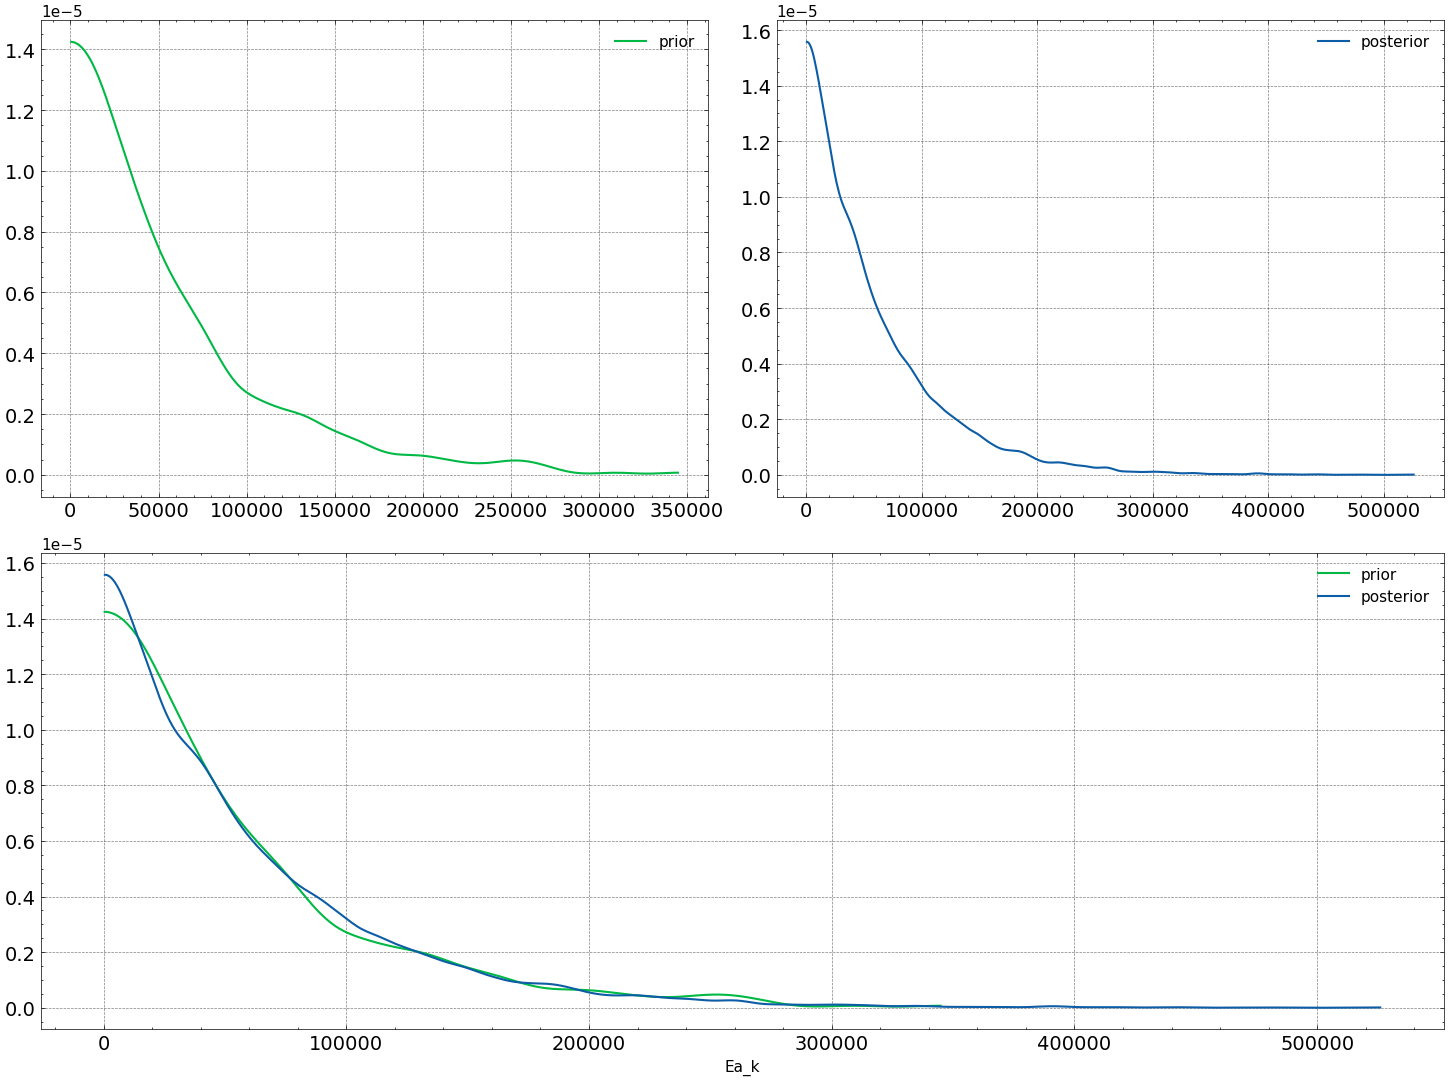

In [12]:
import ICIW_Plots

plt.style.use("ICIWstyle")
az.plot_dist_comparison(
    idata_old,
    var_names=["Ea_k"],
    # figsize=(7, 5),
)

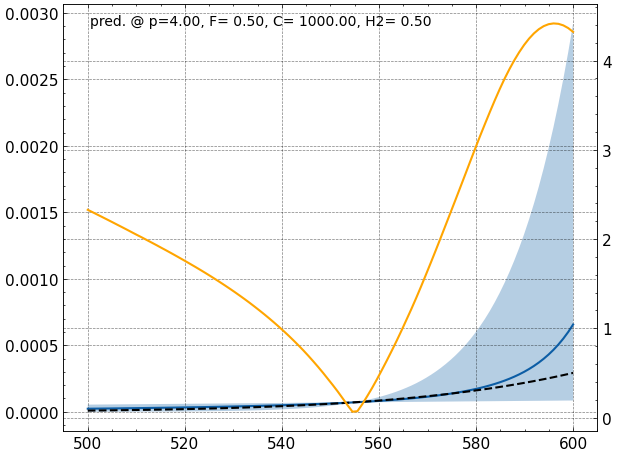

In [13]:
i = 0
Ts = jnp.linspace(500.0, 600.0, 100)
# test_res = post_model_over_T(proposals[i], prior_idata, key="prior")
r = post_model_over_T(proposals[i], idata_old, key="posterior")
true_res_T = true_model_over_T(proposals[i])
plot_post_model_at_proposal(proposals[i], r, true_res_T, Ts)

# Repeat with the newly added point

In [14]:
aug_proposals = np.array(
    [
        [555.0, 4.0, 0.5, 1000.0, 0.5],
        [555.0, 20.0, 0.5, 1000.0, 0.5],
        [600.0, 4.0, 0.5, 1000.0, 0.5],
        # [555.0, 4.0, 0.5, 1000.0, 0.5],
    ]
)
T_aug, p_aug, c2h_aug, f_aug, c2i_aug, r_obs_aug = observe_at_proposal(aug_proposals)
aug_model = bmodel(
    (
        np.asarray(T_aug),
        np.asarray(p_aug),
        np.asarray(c2h_aug),
        np.asarray(f_aug),
        np.asarray(c2i_aug),
    ),
    np.asarray(r_obs_aug),
)
with aug_model:
    aug_idata = pm.sample(
        tune=1000,
        draws=4000,
        chains=4,
        target_accept=0.9,
        return_inferencedata=True,
    )
aug_logp_fun = aug_model.compile_logp()

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 49 seconds.


In [15]:
aug_idata.prior = prior_idata.prior

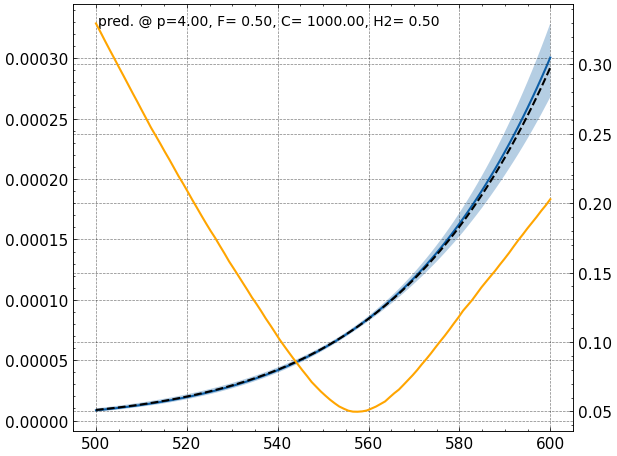

In [16]:
i = 0
Ts = jnp.linspace(500.0, 600.0, 100)
# test_res = post_model_over_T(proposals[i], prior_idata, key="prior")
r = post_model_over_T(aug_proposals[i], aug_idata, key="posterior")
true_res_T = true_model_over_T(aug_proposals[i])
plot_post_model_at_proposal(aug_proposals[i], r, true_res_T, Ts)

array([[<Axes: >, <Axes: >, <Axes: xlabel='Ea_k'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='sigma_r'>]], dtype=object)

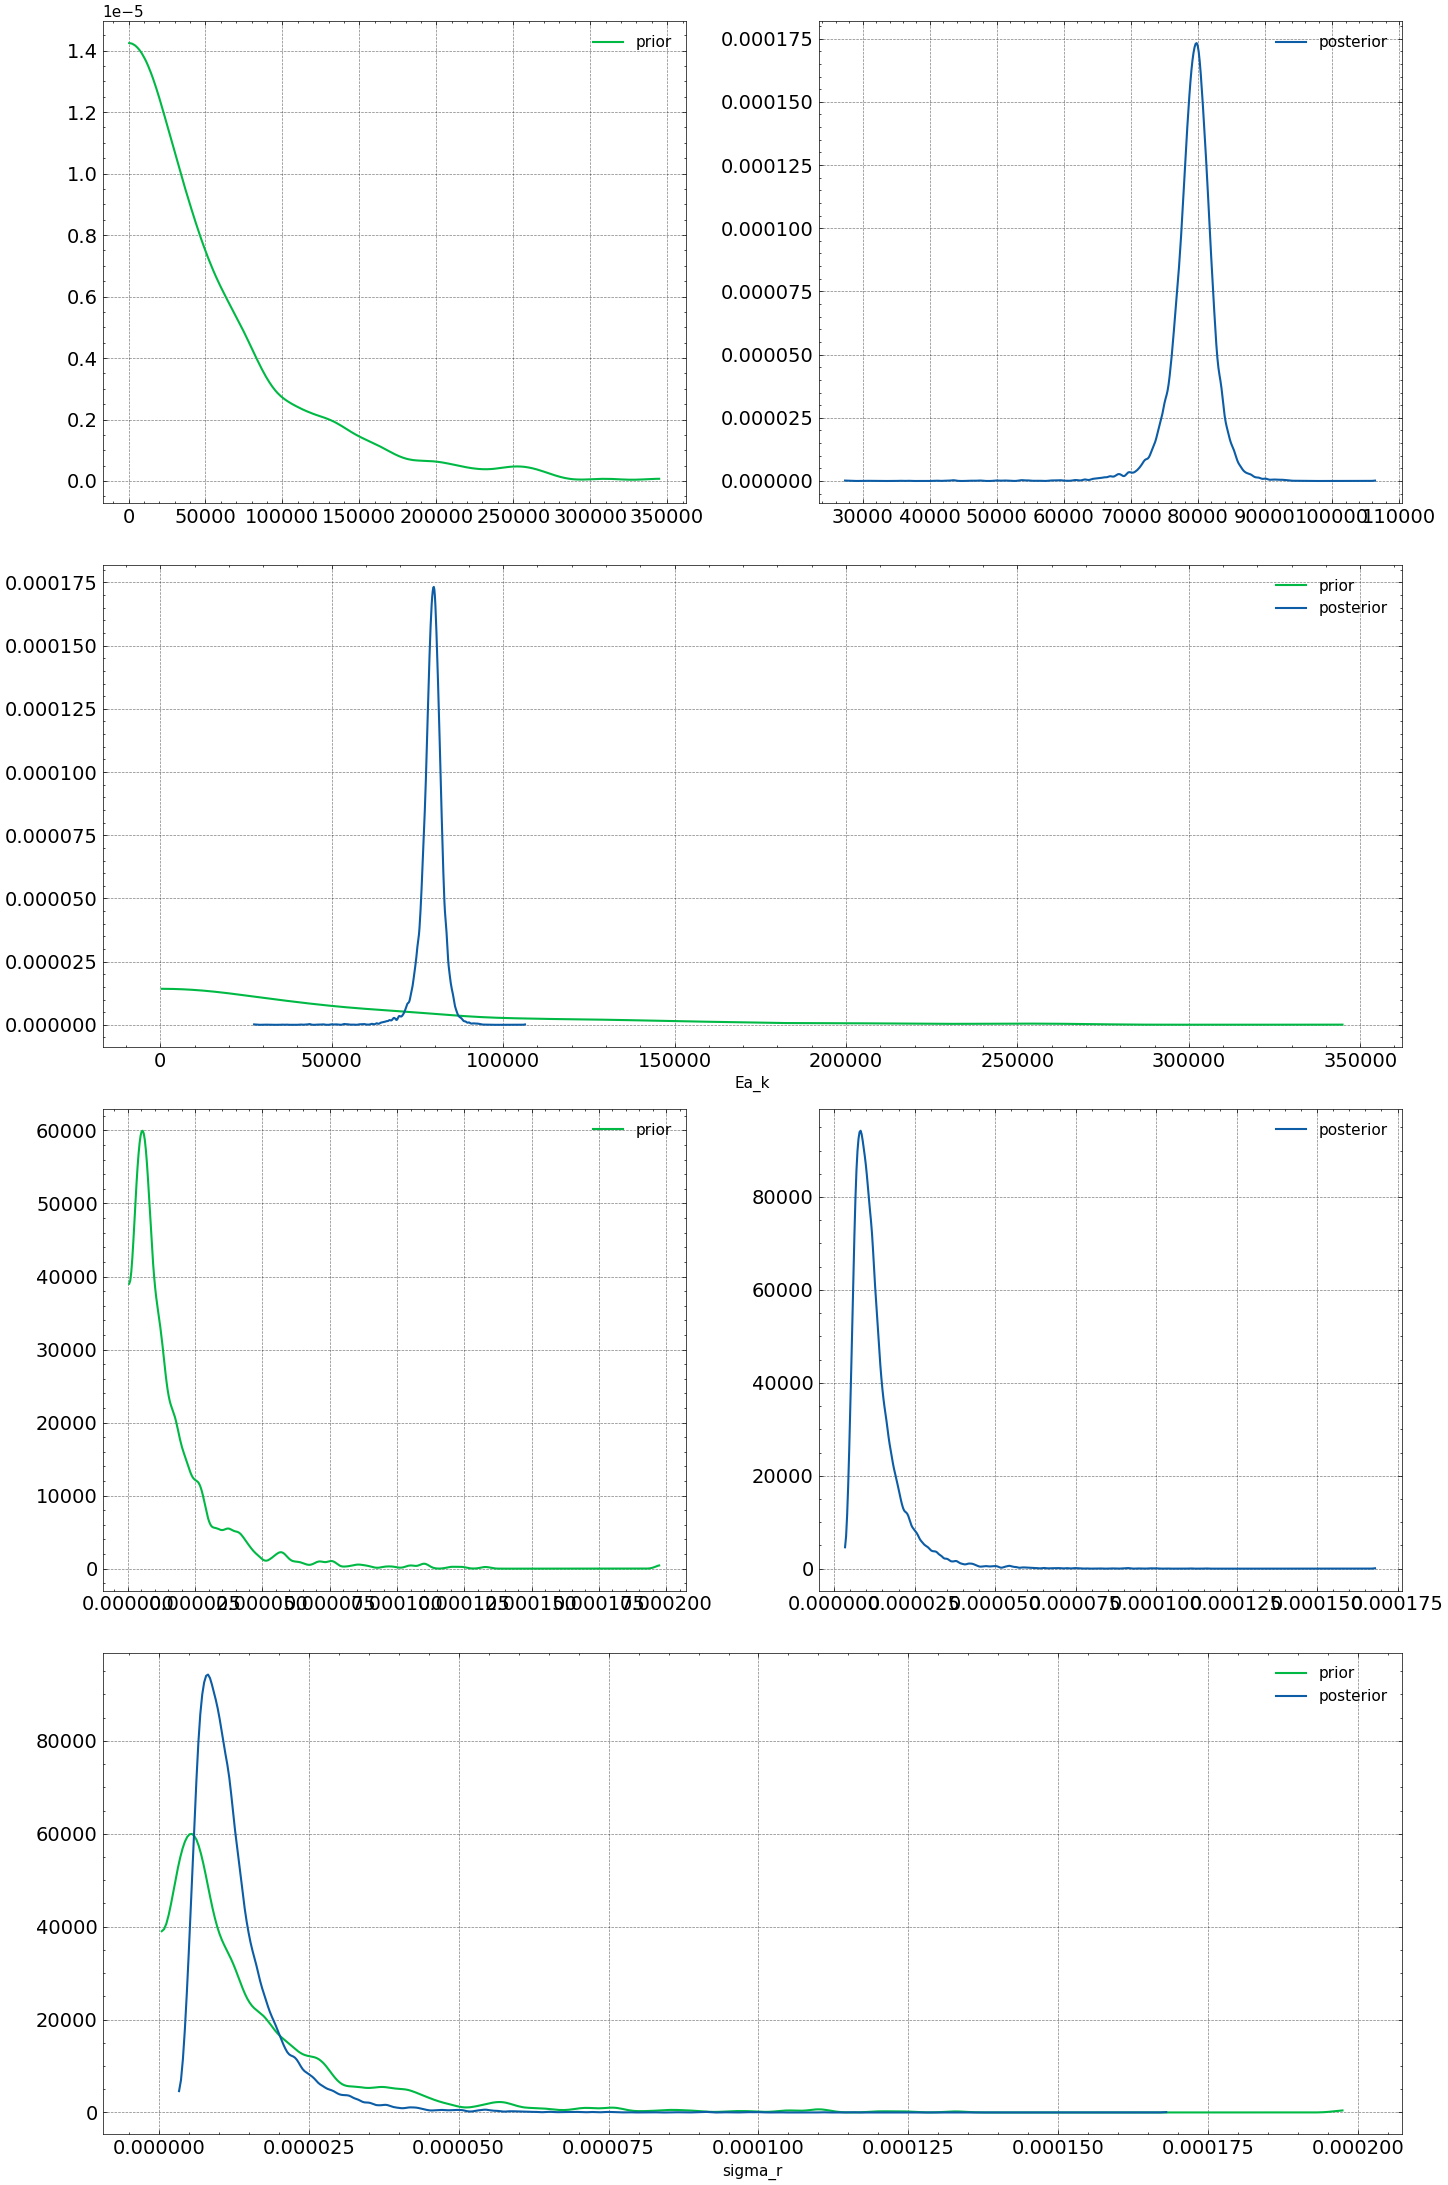

In [17]:
az.plot_dist_comparison(
    aug_idata,
    var_names=[
        "Ea_k",
        # "k0",
        # "dH_oh",
        # "dH_h2",
        # "dH_mix",
        # "A_oh",
        # "A_h2",
        # "A_mix",
        "sigma_r",
    ],
)

### measure the divergence between the two distributions

In [18]:
# Step 3: Compute log probabilities for KL divergence
# Extract parameter samples from both posteriors
old_samples = az.extract(
    idata_old,
    group="posterior",
    num_samples=1000,
    var_names=[
        "Ea_k",
        "k0",
        "dH_oh",
        "dH_h2",
        "dH_mix",
        "A_oh",
        "A_h2",
        "A_mix",
        "sigma_r",
        # "~y_hat",
    ],
)
new_samples = az.extract(
    aug_idata,
    group="posterior",
    num_samples=1000,
    var_names=[
        "Ea_k",
        "k0",
        "dH_oh",
        "dH_h2",
        "dH_mix",
        "A_oh",
        "A_h2",
        "A_mix",
        "sigma_r",
        # "~y_hat",
    ],
)
# Compute KL divergence using marginal distributions
for var in old_samples.data_vars:
    P_samples = new_samples[var].values.flatten()
    Q_samples = old_samples[var].values.flatten()
    kl_div = kl_marginal(P_samples, Q_samples)
    print(f"KL divergence for {var}: {kl_div}")

KL divergence for Ea_k: 2.8598306591137144
KL divergence for k0: 0.005958227350850947
KL divergence for dH_oh: 0.008712646190080029
KL divergence for dH_h2: 0.008949289442135912
KL divergence for dH_mix: 0.002865689090157345
KL divergence for A_oh: 0.006279767026071676
KL divergence for A_h2: 0.04668953724218529
KL divergence for A_mix: 0.01341827712422247
KL divergence for sigma_r: 0.9684190069657278


### This works!

## test the KL divergence calculation

In [20]:
new_proposal = jnp.array(
    [580.0, 4.0, 0.5, 1000.0, 0.5],
)
klds = KL_divergence(
    proposals[:, :],
    r_obs,
    new_proposal.squeeze(),
    idata_old,
    n_hyp_samples=5,
)

Generated 5 hypothetical observations at new condition
Processing hypothetical sample 1/5


Finished [100%]: Average Loss = 1.0114e+12


Processing hypothetical sample 2/5


Finished [100%]: Average Loss = 20,243


Processing hypothetical sample 3/5


Finished [100%]: Average Loss = 1.286e+06


Processing hypothetical sample 4/5


Finished [100%]: Average Loss = 5.9521e+05


Processing hypothetical sample 5/5


Finished [100%]: Average Loss = 49,455


In [21]:
display(klds.sum(dim="parameter").mean().item())

57.546934362152264

In [23]:
new_proposal = jnp.array(
    [555.0, 4.0, 0.5, 1000.0, 0.5],
)
klds_bad = KL_divergence(
    proposals[:, :],
    r_obs,
    new_proposal.squeeze(),
    idata_old,
    n_hyp_samples=5,
)

Generated 5 hypothetical observations at new condition
Processing hypothetical sample 1/5


Finished [100%]: Average Loss = 19,153


Processing hypothetical sample 2/5


Finished [100%]: Average Loss = 20,864


Processing hypothetical sample 3/5


Finished [100%]: Average Loss = 19,833


Processing hypothetical sample 4/5


Finished [100%]: Average Loss = 19,677


Processing hypothetical sample 5/5


Finished [100%]: Average Loss = 20,694


In [24]:
display(klds_bad.sum(dim="parameter").mean().item())

50.92298293928731

## Select the most informative point:

In [26]:
Ts = jnp.linspace(500.0, 600.0, 20)
KLDs = []

for T in Ts:
    new_proposal = jnp.array(
        [T, 4.0, 0.5, 1000.0, 0.5],
    )
    KLDs.append(
        KL_divergence(
            proposals[:, :],
            r_obs,
            new_proposal.squeeze(),
            idata_old,
            n_hyp_samples=5,
        )
    )

Generated 5 hypothetical observations at new condition
Processing hypothetical sample 1/5


Finished [100%]: Average Loss = 19,515


Processing hypothetical sample 2/5


Finished [100%]: Average Loss = 19,449


Processing hypothetical sample 3/5


...

Processing hypothetical sample 4/5


Finished [100%]: Average Loss = 1.953e+13


Processing hypothetical sample 5/5


Finished [100%]: Average Loss = 1.2508e+05


TypeError: _sum() got an unexpected keyword argument 'dim'

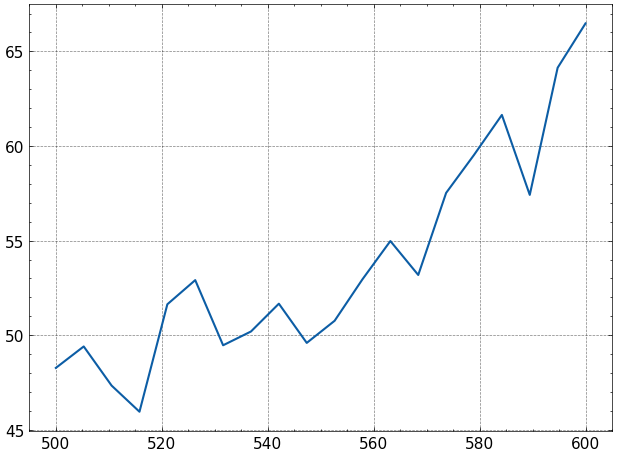

In [30]:
KLDs.shape
plt.plot(Ts, KLDs.sum(axis=2).mean(axis=1))

In [ ]:
KLDs = []
for T in Ts:
    new_proposal = jnp.array(
        [T, 4.0, 0.5, 1000.0, 0.5],
    )
    KLDs.append(
        mp_KL_divergence(
            proposals[:, :],
            r_obs,
            new_proposal.squeeze(),
            idata_old,
            n_hyp_samples=5,
        )
    )

Generated 5 hypothetical observations at new condition
